### Tests of the channels

In [1]:
%matplotlib widget

import numpy as np
import matplotlib.pyplot as plt
from scipy.constants import c, pi

from utils.utils import *
from components.ris import RIS
from components.antenna import Antenna
from channels.tx_ris_rx_channel import tx_ris_rx_channel

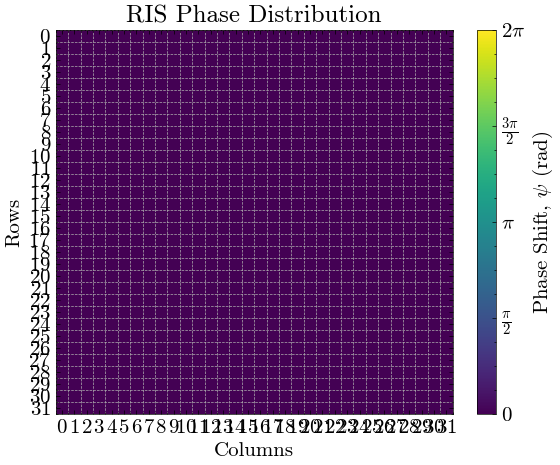

In [2]:
# Create RIS
f = 28e9
lam = c/f

ris = RIS(center=[0,0,0],boresight='z',Ncol=32,Nrow=32,delta_h=lam/2,delta_v=lam/2,dx=0.47*lam,dy=0.47*lam,fc=f,radiation_factor=1,phase_shifts_dict={"0": 0,"1": pi},att_dict={"0": 1,"1": 1})

ris.plot_phase_dist()

In [3]:
# Create antennas and channel
tx_pos = sph2cart([10.01,0,0])
rx_pos = sph2cart([11,180,30])

tx_antenna = Antenna(tx_pos,0)
rx_antenna = Antenna(rx_pos,0)

channel = tx_ris_rx_channel(tx_antenna=tx_antenna,rx_antenna=rx_antenna,ris=ris,model='Tang_general')


Default state of RIS:


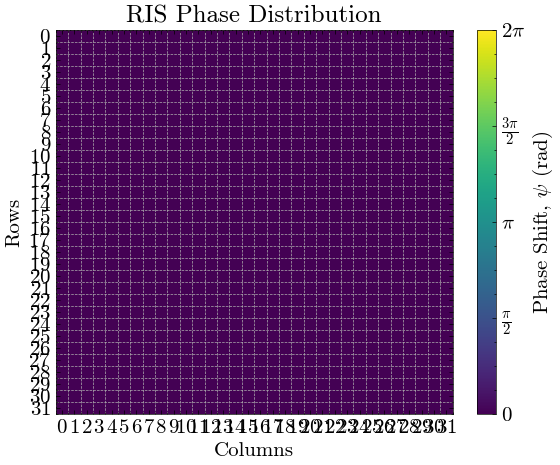

Optimized state of perfect RIS:


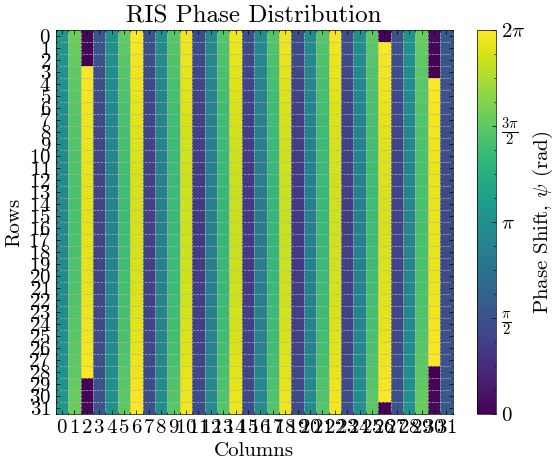

Optimized state of normal RIS (direct dic. alg.):


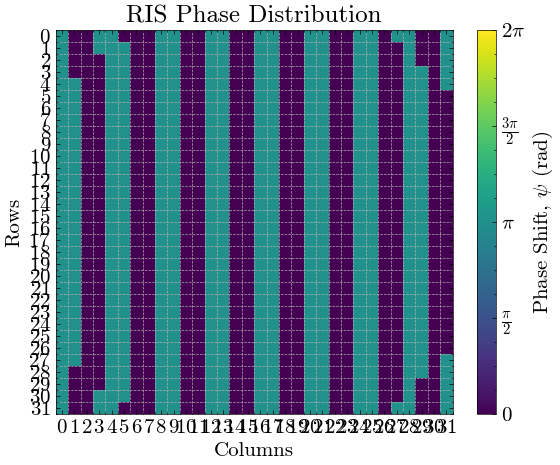

Optimized state of normal RIS (max bf alg.):
Optimum value of α: 2.106 rad


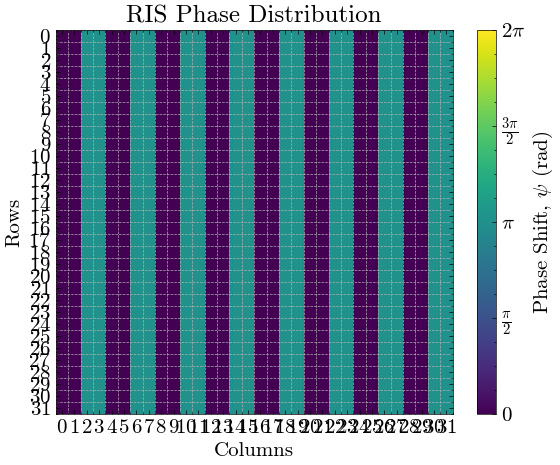

In [4]:
# Optimize channel and see the return

# Optimize channel and see the return
print("Default state of RIS:")
ris.plot_phase_dist()

print("Optimized state of perfect RIS:")
channel.optimize(mode='cont')
ris.plot_phase_dist()

print("Optimized state of normal RIS (direct dic. alg.):")
channel.optimize(optimizer='direct_disc', mode='disc')
ris.plot_phase_dist()

print("Optimized state of normal RIS (max bf alg.):")
channel.optimize(optimizer='max_bf', mode='disc')
ris.plot_phase_dist()

Beamforming normalized at RX location with continuous shifts: 1.000


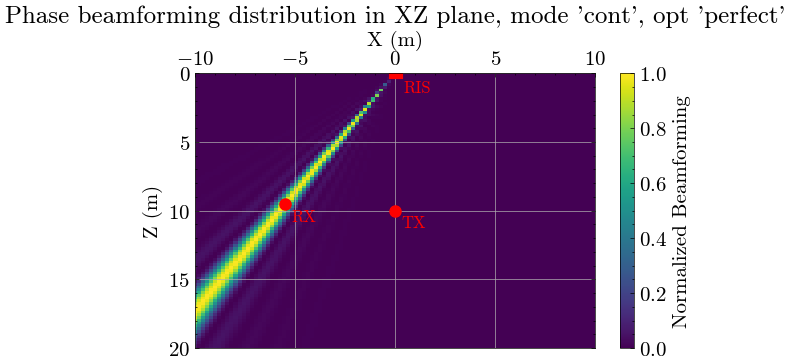

Beamforming normalized at RX location with direct discretization shifts: 0.454


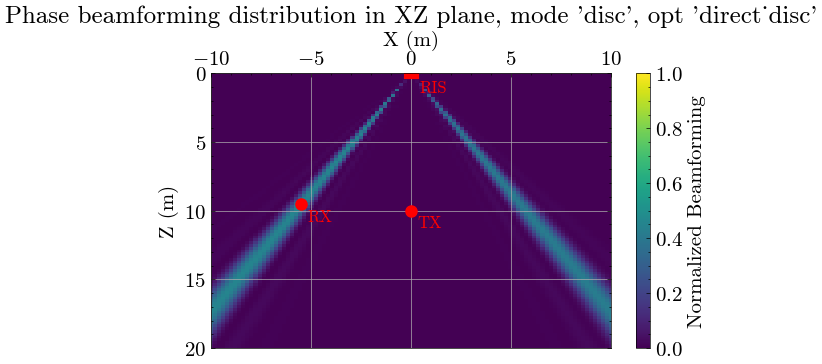

Optimum value of α: 2.106 rad
Beamforming normalized at RX location with max bf discretization shifts: 0.487


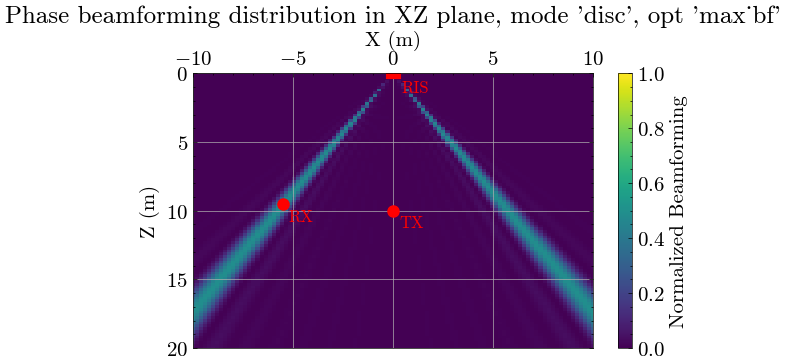

In [5]:
# Try phase beamforming function:

# Generate rx locations as a 2D map
xlim = [-10, 10]
zlim = [0, 20]
Nx = 100
Nz = 100

maximum_bf = (ris.Nrow * ris.Ncol)**2

# Optimize the channel with each optimizer and mode and see the phase beamforming:
channel.optimize(mode='cont')
print(f"Beamforming normalized at RX location with continuous shifts: {channel.phase_bf_multrx(rx_pos[0])[0] / maximum_bf:.3f}")
channel.plot_phase_bf_2d_map(ax1lim=xlim,ax2lim=zlim,Nax1=Nx,Nax2=Nz,plane='xz')

channel.optimize(optimizer='direct_disc', mode='disc')
print(f"Beamforming normalized at RX location with direct discretization shifts: {channel.phase_bf_multrx(rx_pos[0])[0] / maximum_bf:.3f}")
channel.plot_phase_bf_2d_map(ax1lim=xlim,ax2lim=zlim,Nax1=Nx,Nax2=Nz,plane='xz')

channel.optimize(optimizer='max_bf', mode='disc')
print(f"Beamforming normalized at RX location with max bf discretization shifts: {channel.phase_bf_multrx(rx_pos[0])[0] / maximum_bf:.3f}")
channel.plot_phase_bf_2d_map(ax1lim=xlim,ax2lim=zlim,Nax1=Nx,Nax2=Nz,plane='xz')

Path gain at RX location with continuous shifts: -95.169 dB


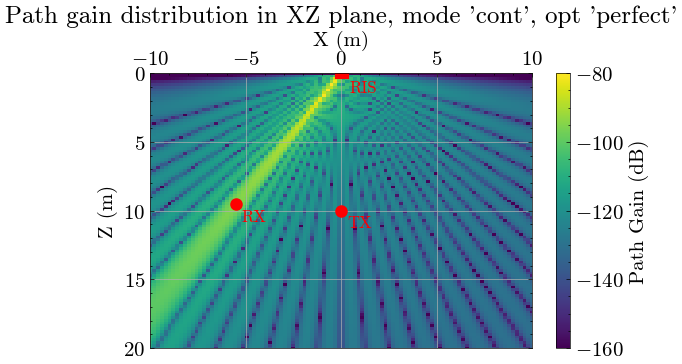

Path gain at RX location with direct disc. shifts: -98.598 dB


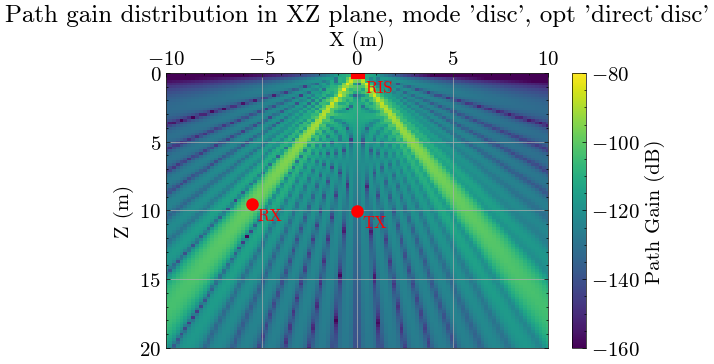

Optimum value of α: 2.106 rad
Path gain at RX location with max bf disc. shifts: -98.294 dB


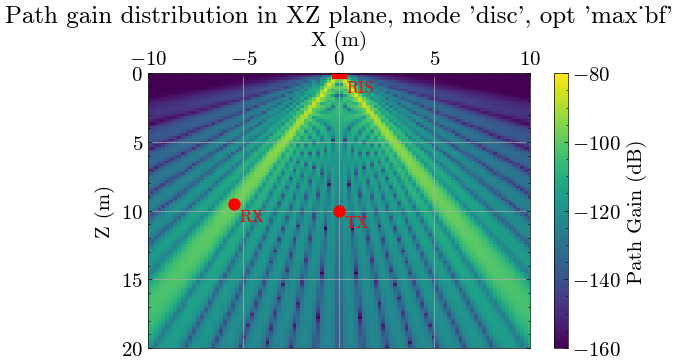

In [6]:
# Try path gain function:

# Generate rx locations as a 2D map
xlim = [-10, 10]
zlim = [0, 20]
Nx = 100
Nz = 100
vmin = -160
vmax = -80

channel.optimize(mode='cont')
print(f"Path gain at RX location with continuous shifts: {10*np.log10(channel.path_gain_multrx(rx_pos[0])[0]):.3f} dB")
channel.plot_path_gain_2d_map(ax1lim=xlim,ax2lim=zlim,Nax1=Nx,Nax2=Nz,plane='xz',vmin=vmin,vmax=vmax)

channel.optimize(optimizer='direct_disc', mode='disc')
print(f"Path gain at RX location with direct disc. shifts: {10*np.log10(channel.path_gain_multrx(rx_pos[0])[0]):.3f} dB")
channel.plot_path_gain_2d_map(ax1lim=xlim,ax2lim=zlim,Nax1=Nx,Nax2=Nz,plane='xz',vmin=vmin,vmax=vmax)

channel.optimize(optimizer='max_bf', mode='disc')
print(f"Path gain at RX location with max bf disc. shifts: {10*np.log10(channel.path_gain_multrx(rx_pos[0])[0]):.3f} dB")
channel.plot_path_gain_2d_map(ax1lim=xlim,ax2lim=zlim,Nax1=Nx,Nax2=Nz,plane='xz',vmin=vmin,vmax=vmax)

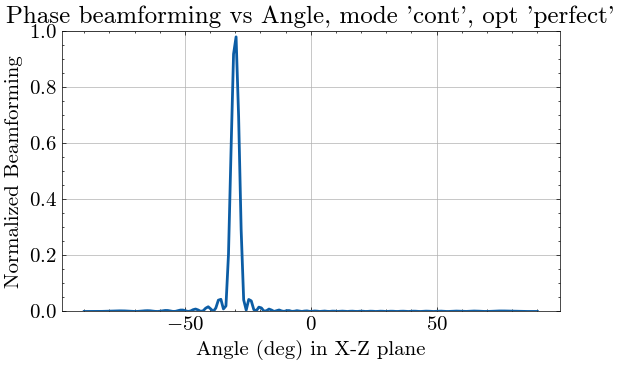

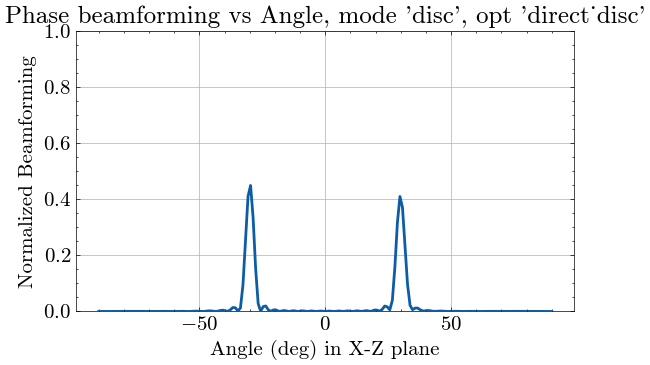

Optimum value of α: 2.106 rad


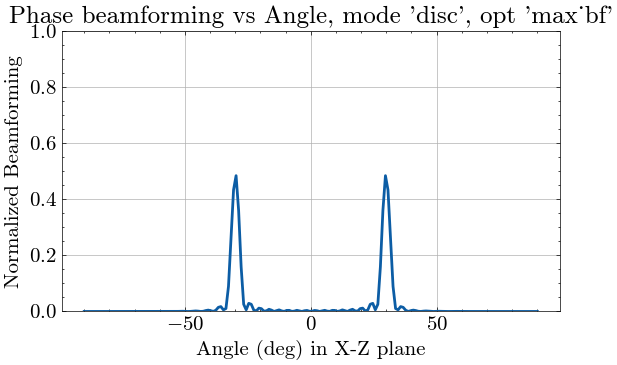

In [7]:
channel.optimize(mode='cont')
channel.plot_phase_bf_angle(r=11,Nr=180,axis='x')

channel.optimize(optimizer='direct_disc', mode='disc')
channel.plot_phase_bf_angle(r=11,Nr=180,axis='x')

channel.optimize(optimizer='max_bf', mode='disc')
channel.plot_phase_bf_angle(r=11,Nr=180,axis='x')

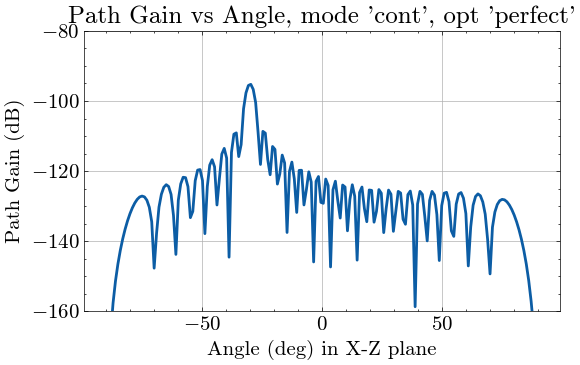

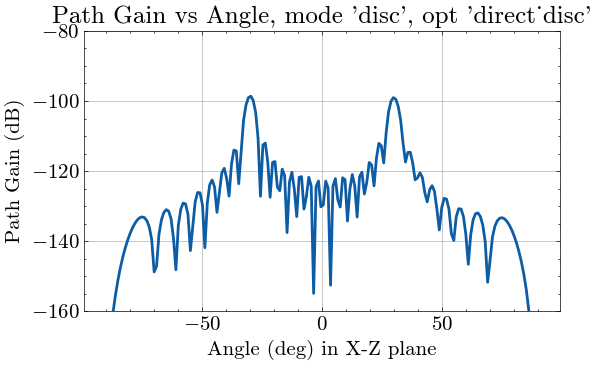

Optimum value of α: 2.106 rad


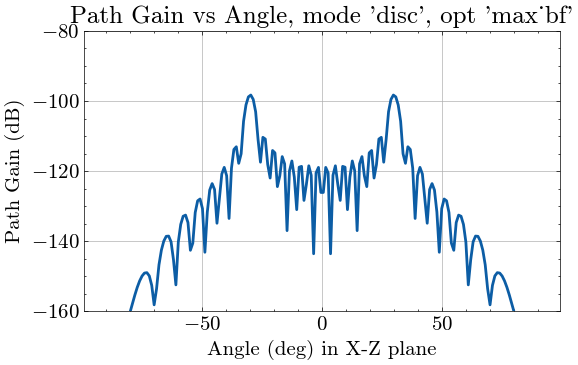

In [8]:
channel.optimize(mode='cont')
channel.plot_path_gain_angle(r=11,Nr=180,axis='x',vmin=vmin,vmax=vmax)

channel.optimize(optimizer='direct_disc', mode='disc')
channel.plot_path_gain_angle(r=11,Nr=180,axis='x',vmin=vmin,vmax=vmax)

channel.optimize(optimizer='max_bf', mode='disc')
channel.plot_path_gain_angle(r=11,Nr=180,axis='x',vmin=vmin,vmax=vmax)

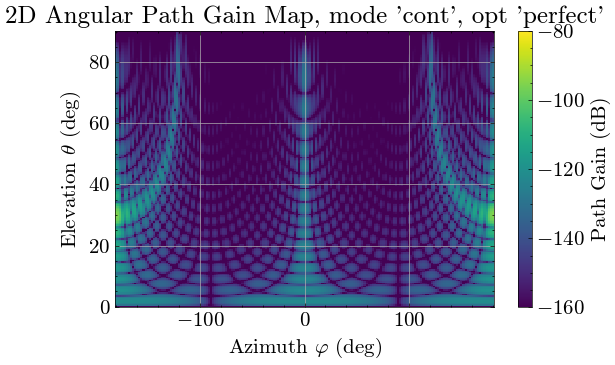

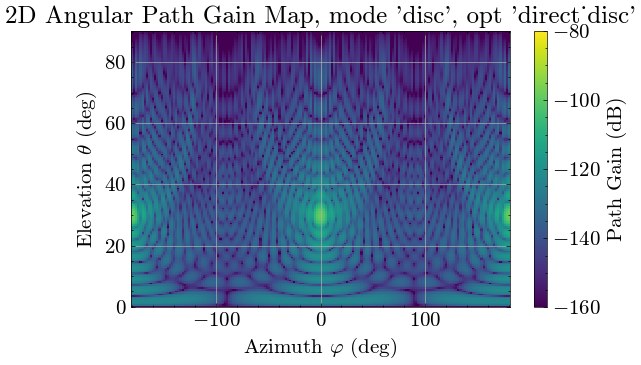

Optimum value of α: 2.106 rad


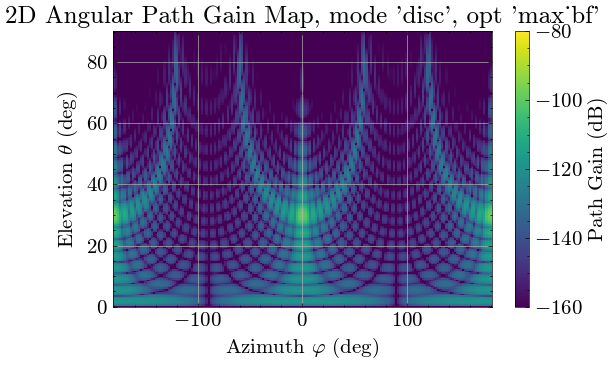

In [9]:
channel.optimize(mode='cont')
channel.plot_path_gain_angle_2d_map(r=11,Nr=180,vmin=vmin,vmax=vmax)

channel.optimize(optimizer='direct_disc', mode='disc')
channel.plot_path_gain_angle_2d_map(r=11,Nr=180,vmin=vmin,vmax=vmax)

channel.optimize(optimizer='max_bf', mode='disc')
channel.plot_path_gain_angle_2d_map(r=11,Nr=180,vmin=vmin,vmax=vmax)

c:\Users\UPV\Documents\GitHub\surpRISe\channels\tx_ris_rx_channel.py:372: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure(figsize=(6, 4))


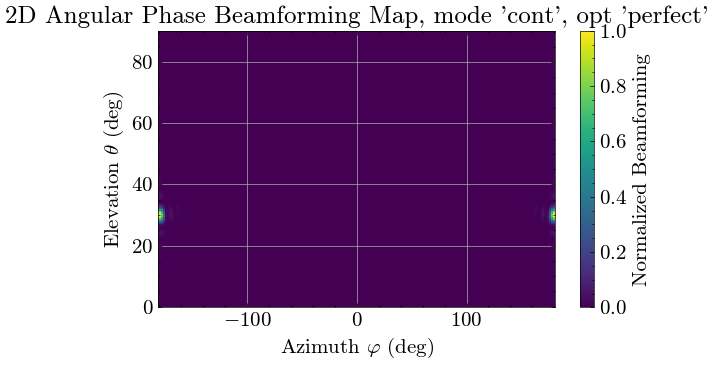

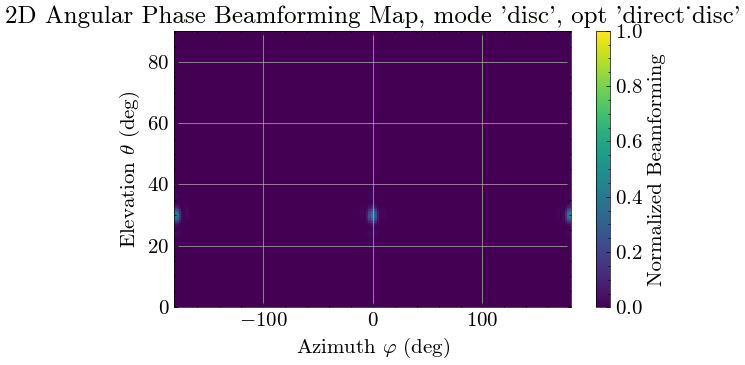

Optimum value of α: 2.106 rad


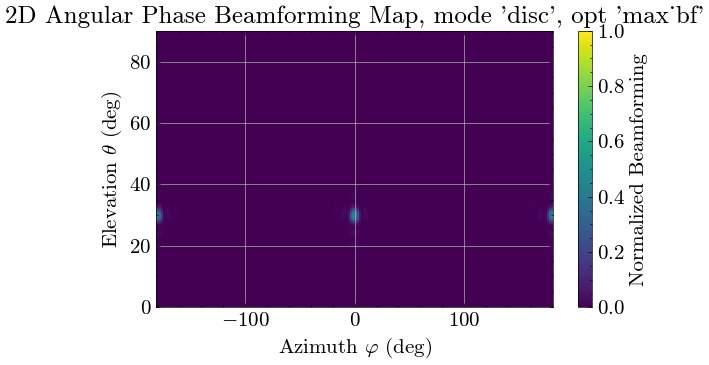

In [10]:
channel.optimize(mode='cont')
channel.plot_phase_bf_angle_2d_map(r=11,Nr=180)

channel.optimize(optimizer='direct_disc', mode='disc')
channel.plot_phase_bf_angle_2d_map(r=11,Nr=180)

channel.optimize(optimizer='max_bf', mode='disc')
channel.plot_phase_bf_angle_2d_map(r=11,Nr=180)